# 2. Turn each photo into numbers

Linear regression, logistic regression, random forest and XGBoost **cannot read raw photos**. They need a table of numbers. Here, each photo becomes one row of measurements:

- **Colour and brightness:** the overall look of the photo.
- **Dark spots:** these can be haemorrhages.
- **Bright and yellow spots:** these can be exudates.
- **Location:** whether changes are near the centre or the edge.

**Important:** we choose these measurements by hand, so these models only see what we measure. A neural network learns its own features from the pixels, so it may do better.

We do **not** use image size, patient ID or file names, because they could teach the model a shortcut.

This notebook may take 5 to 20 minutes. If it stops, run it again and it will continue where it left off.

In [1]:
%pip install -q numpy pandas scipy pillow matplotlib

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'c:\\Users\\Administrator\\Desktop\\AfriEyeSamsung\\.venv\\Lib\\site-packages\\PIL\\_imaging.cp311-win_amd64.pyd'
Check the permissions.


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "DeepDRiD" / "regular_fundus_images"
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for folder in (PROCESSED, RESULTS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)
print("Project folder:", ROOT)

Project folder: c:\Users\Administrator\Desktop\AfriEyeSamsung


In [3]:
import time

import numpy as np
import pandas as pd
from PIL import Image

In [4]:
import matplotlib.pyplot as plt

BLUE, TEAL, ORANGE, PURPLE = "#1F4E9E", "#00948F", "#C4581F", "#7A3E9D"
INK, MUTED, GRID = "#1B2433", "#566173", "#E3E7F0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.edgecolor": "#AEB6C5", "axes.labelcolor": MUTED, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "legend.frameon": False,
})

In [5]:
from scipy import ndimage as ndi
from scipy.stats import kurtosis, skew

SIZE = 512
yy, xx = np.mgrid[0:SIZE, 0:SIZE]
RADIUS = np.hypot(xx - (SIZE - 1) / 2, yy - (SIZE - 1) / 2) / (SIZE / 2)
MASK = RADIUS < 0.92
RINGS = {"centre": RADIUS < 0.35, "middle": (RADIUS >= 0.35) & (RADIUS < 0.65), "outer": (RADIUS >= 0.65) & (RADIUS < 0.92)}


def crop_square(image, threshold=18):
    """Crop to the bright retina, then pad to a square so the shape is not stretched."""
    image = image.convert("RGB")
    small = image.copy(); small.thumbnail((256, 256))
    scale = image.width / small.width
    keep = np.asarray(small).max(axis=2) > threshold
    if keep.mean() > .02:
        ys, xs = np.where(keep)
        image = image.crop((int(xs.min() * scale), int(ys.min() * scale), int((xs.max() + 1) * scale), int((ys.max() + 1) * scale)))
    side = max(image.size)
    square = Image.new("RGB", (side, side))
    square.paste(image, ((side - image.width) // 2, (side - image.height) // 2))
    return square.resize((SIZE, SIZE), Image.BILINEAR)


def count_blobs(mask, low=4, high=250):
    labels, n = ndi.label(mask)
    if n == 0:
        return 0, 0.0
    areas = ndi.sum_labels(mask, labels, index=np.arange(1, n + 1))
    small = areas[(areas >= low) & (areas <= high)]
    return len(small), float(small.sum())


def image_features(path):
    a = np.asarray(crop_square(Image.open(path)), dtype=np.float32)
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    out = {}
    for name, channel in (("red", r), ("green", g), ("blue", b)):
        v = channel[MASK]
        out[f"{name}_mean"], out[f"{name}_std"] = v.mean(), v.std()
        out[f"{name}_p05"], out[f"{name}_p50"], out[f"{name}_p95"] = np.percentile(v, [5, 50, 95])

    # Remove the slow background, so small details stand out.
    green_detail = g - ndi.gaussian_filter(g, 25)
    v = green_detail[MASK]
    out.update(detail_std=v.std(), detail_skew=skew(v), detail_kurtosis=kurtosis(v), detail_p01=np.percentile(v, 1), detail_p99=np.percentile(v, 99))
    out["sharpness"] = ndi.laplace(ndi.gaussian_filter(g, 1))[MASK].std()

    # Dark spots can be haemorrhages. Bright spots can be exudates. Three sizes, two strengths.
    for sigma in (1, 2, 4):
        dog = ndi.gaussian_filter(g, sigma) - ndi.gaussian_filter(g, sigma * 2)
        for t in (4, 8):
            dark, bright = (dog < -t) & MASK, (dog > t) & MASK
            out[f"dark_share_s{sigma}_t{t}"] = dark.sum() / MASK.sum()
            out[f"bright_share_s{sigma}_t{t}"] = bright.sum() / MASK.sum()
            out[f"dark_blobs_s{sigma}_t{t}"], out[f"dark_blob_area_s{sigma}_t{t}"] = count_blobs(dark)
            out[f"bright_blobs_s{sigma}_t{t}"], out[f"bright_blob_area_s{sigma}_t{t}"] = count_blobs(bright)

    # Exudates look yellow: high red and green, with low blue.
    yellow = (r + g) / 2 - b
    yellow_detail = yellow - ndi.gaussian_filter(yellow, 25)
    for t in (10, 20):
        spots = (yellow_detail > t) & MASK
        out[f"yellow_share_t{t}"] = spots.sum() / MASK.sum()
        out[f"yellow_blobs_t{t}"], out[f"yellow_blob_area_t{t}"] = count_blobs(spots)

    # Where the changes are: centre, middle or outer retina.
    for ring, part in RINGS.items():
        out[f"{ring}_detail_abs"] = np.abs(green_detail[part]).mean()
        out[f"{ring}_dark_share"] = (green_detail[part] < -10).mean()
        out[f"{ring}_bright_share"] = (green_detail[part] > 10).mean()
    return {k: float(v) for k, v in out.items()}

## See what the features measure

The first picture is the photo after cropping. The others show the detail that the feature code measures.

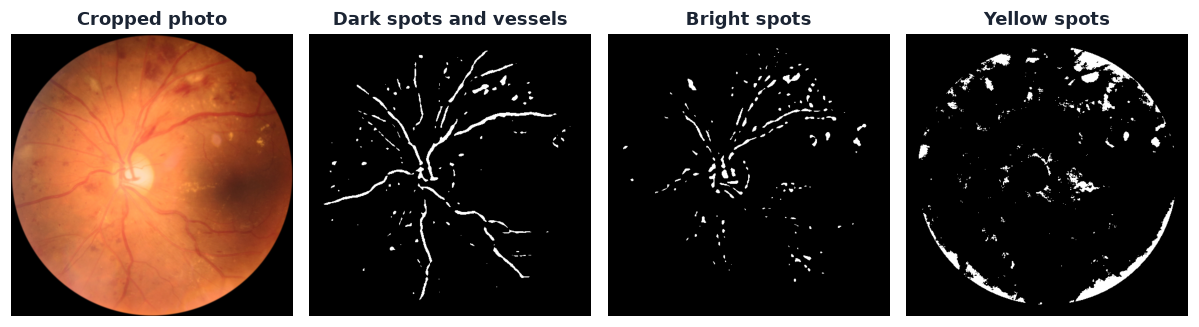

In [6]:
labels = pd.read_csv(PROCESSED / "clean_labels.csv")
example = labels[(labels.grade == 4) & (labels.quality == 1)].iloc[0]
a = np.asarray(crop_square(Image.open(example.path)), dtype=np.float32)
g = a[..., 1]
dog = ndi.gaussian_filter(g, 2) - ndi.gaussian_filter(g, 4)
yellow = (a[..., 0] + a[..., 1]) / 2 - a[..., 2]; yellow_detail = yellow - ndi.gaussian_filter(yellow, 25)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
axes[0].imshow(a.astype(np.uint8)); axes[0].set_title("Cropped photo")
axes[1].imshow((dog < -4) & MASK, cmap="gray"); axes[1].set_title("Dark spots and vessels")
axes[2].imshow((dog > 4) & MASK, cmap="gray"); axes[2].set_title("Bright spots")
axes[3].imshow((yellow_detail > 10) & MASK, cmap="gray"); axes[3].set_title("Yellow spots")
for ax in axes: ax.axis("off")
fig.tight_layout(); plt.show()

## Measure every photo

Progress is saved every 100 photos in `data/processed/features.csv`.

In [7]:
FILE = PROCESSED / "features.csv"
done = pd.read_csv(FILE) if FILE.exists() else pd.DataFrame()
finished = set(done.image_id) if len(done) else set()
todo = labels[~labels.image_id.isin(finished)]
print(f"{len(finished)} already done, {len(todo)} to do")

rows, start = [], time.time()
for count, row in enumerate(todo.itertuples(), 1):
    rows.append({"image_id": row.image_id, **image_features(row.path)})
    if count % 100 == 0 or count == len(todo):
        done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True); done.to_csv(FILE, index=False); rows = []
        minutes = (time.time() - start) / 60
        print(f"{count}/{len(todo)} photos, {minutes:.1f} minutes", flush=True)

features = pd.read_csv(FILE)
print("Feature table:", features.shape)

0 already done, 2000 to do
100/2000 photos, 2.6 minutes
200/2000 photos, 5.1 minutes
300/2000 photos, 6.1 minutes
400/2000 photos, 7.2 minutes
500/2000 photos, 7.9 minutes
600/2000 photos, 8.9 minutes
700/2000 photos, 9.8 minutes
800/2000 photos, 10.6 minutes
900/2000 photos, 11.4 minutes
1000/2000 photos, 12.1 minutes
1100/2000 photos, 12.9 minutes
1200/2000 photos, 13.8 minutes
1300/2000 photos, 14.6 minutes
1400/2000 photos, 15.4 minutes
1500/2000 photos, 16.3 minutes
1600/2000 photos, 17.1 minutes
1700/2000 photos, 18.1 minutes
1800/2000 photos, 19.0 minutes
1900/2000 photos, 19.7 minutes
2000/2000 photos, 20.5 minutes
Feature table: (2000, 73)


## Check the features

We use the **training split only** here. Looking at test data while choosing features would make the final score less trustworthy.

Rows with a missing value: 0
Features with no variation: []


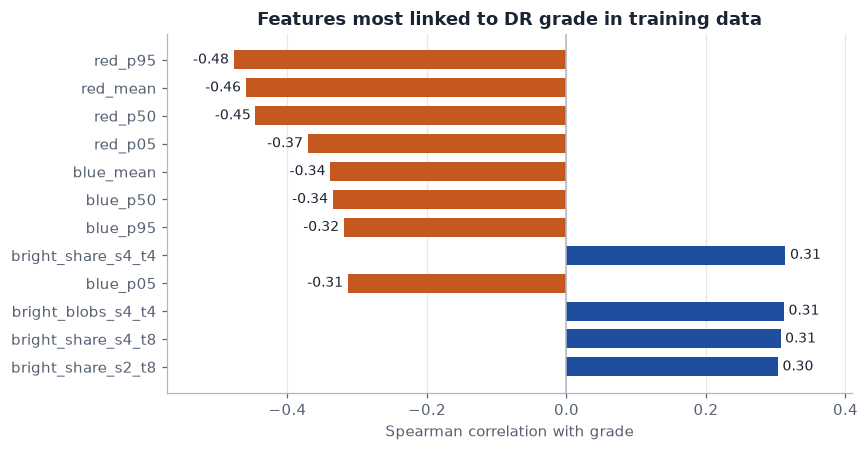

In [8]:
table = labels.merge(features, on="image_id")
cols = [c for c in features.columns if c != "image_id"]
print("Rows with a missing value:", int(table[cols].isna().any(axis=1).sum()))
print("Features with no variation:", [c for c in cols if table[c].std() == 0])

train = table[table.split == "train"]
strength = train[cols].corrwith(train.grade, method="spearman").sort_values(key=np.abs, ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(strength.index, strength.values, color=[BLUE if v > 0 else ORANGE for v in strength.values], height=.68)
ax.bar_label(bars, fmt="%.2f", padding=3, color=INK, fontsize=9); ax.axvline(0, color="#AEB6C5", linewidth=1)
ax.set_title("Features most linked to DR grade in training data"); ax.set_xlabel("Spearman correlation with grade"); ax.grid(axis="y", visible=False)
ax.margins(x=.12); fig.tight_layout(); plt.show()

**Next:** open each model notebook. They can run in any order, and `07_compare_models.ipynb` comes last.